# 01 — EDA: mengenal data harga pangan

Notebook ini melihat data dari tabel `mart` sebelum masuk ke uji statistik dan clustering.

Pertanyaan yang dijawab:
1. Seberapa lengkap datanya, per provinsi dan per tahun?
2. Bagaimana tren harga 2018–2026 per komoditas? (Q1)
3. Seberapa besar perubahan harga dari bulan ke bulan?
4. Komoditas mana yang harganya bergerak bersama?
5. Seperti apa data yang ditandai anomali?

Kecuali disebut lain, semua angka memakai **pasar tradisional**.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
from scipy.cluster import hierarchy

from src.db import query
from src.viz import (CMAP_DIV, CMAP_SEQ, INK_2, MUTED, SEQUENTIAL, SERIES, nama_bulan, save,
                     set_style, subtitle, sumbu_tanggal, warna_label)

set_style()
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Ukuran dan cakupan data

In [2]:
query("""
    SELECT jp.nama_jenis_pasar                 AS jenis_pasar,
           count(*)                            AS baris_harian,
           min(f.tanggal)                      AS mulai,
           max(f.tanggal)                      AS sampai,
           count(DISTINCT f.wilayah_id) - 1    AS provinsi,
           count(DISTINCT f.komoditas_id)      AS varian
    FROM mart.fact_harga_harian AS f
    JOIN mart.dim_jenis_pasar AS jp USING (jenis_pasar_id)
    GROUP BY jp.nama_jenis_pasar, jp.urutan_rantai_pasok
    ORDER BY jp.urutan_rantai_pasok
""")

,jenis_pasar,baris_harian,mulai,sampai,provinsi,varian
0,Produsen,431031,2023-01-02,2026-10-30,33,21
1,Pedagang Besar,690051,2023-01-02,2026-10-30,34,21
2,Pasar Tradisional,1587593,2018-01-01,2026-10-30,34,21
3,Pasar Modern,641761,2023-01-02,2026-10-30,34,21


Pasar tradisional punya data paling panjang (2018–2026). Tiga jenis pasar lainnya diambil mulai
2023 dan hanya dipakai untuk perbandingan antar mata rantai (Q3, Q6). Data produsen tidak ada
untuk satu provinsi.

## 2. Kelengkapan data per provinsi

Kelengkapan = jumlah harga yang tercatat ÷ (hari kerja yang punya data nasional × 21 varian).

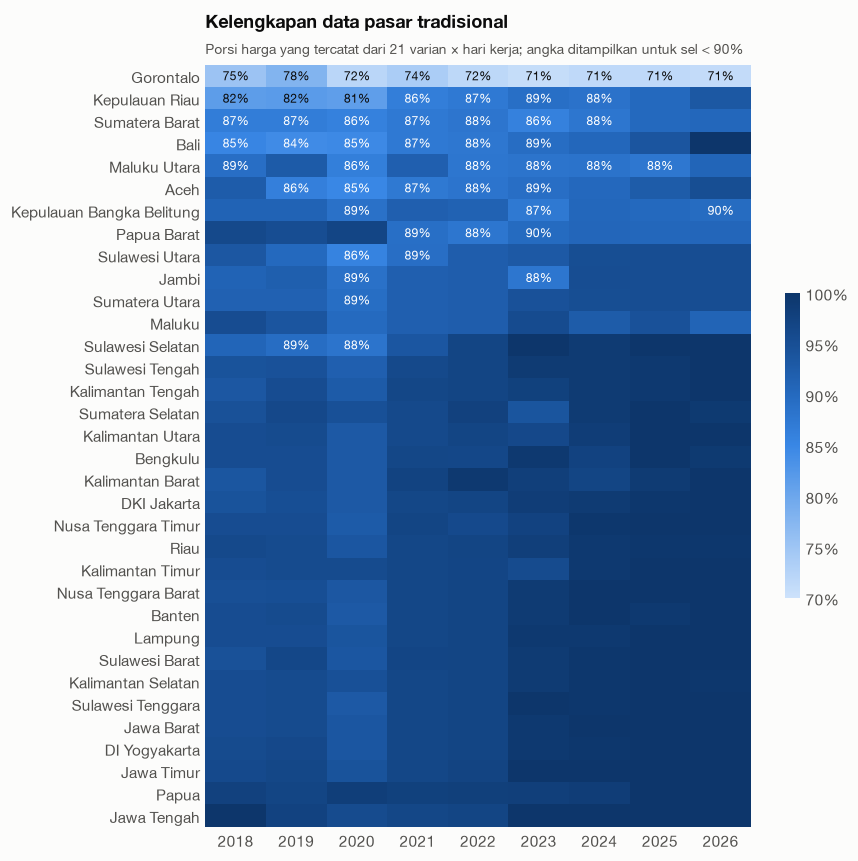

In [3]:
kelengkapan = query("""
    WITH hari AS (
        SELECT extract(year FROM tanggal)::int AS tahun, count(DISTINCT tanggal) AS n_hari
        FROM mart.fact_harga_harian
        WHERE jenis_pasar_id = 1 AND wilayah_id = 0
        GROUP BY 1
    )
    SELECT w.nama_wilayah, extract(year FROM f.tanggal)::int AS tahun,
           count(*)::float / (h.n_hari * 21) AS kelengkapan
    FROM mart.fact_harga_harian AS f
    JOIN mart.dim_wilayah AS w USING (wilayah_id)
    JOIN hari AS h ON h.tahun = extract(year FROM f.tanggal)
    WHERE f.jenis_pasar_id = 1 AND NOT w.is_nasional
    GROUP BY w.nama_wilayah, 2, h.n_hari
""").pivot(index="nama_wilayah", columns="tahun", values="kelengkapan")
kelengkapan = kelengkapan.loc[kelengkapan.mean(axis=1).sort_values().index]

VMIN, VMAX = 0.7, 1.0
fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(kelengkapan, cmap=CMAP_SEQ, vmin=VMIN, vmax=VMAX, aspect="auto")
ax.set_xticks(range(kelengkapan.shape[1]), kelengkapan.columns)
ax.set_yticks(range(kelengkapan.shape[0]), kelengkapan.index)
ax.grid(False)
ax.spines[:].set_visible(False)
# label hanya untuk sel yang kelengkapannya < 90%
for i, row in enumerate(kelengkapan.values):
    for j, v in enumerate(row):
        if v < 0.9:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                    color=warna_label((v - VMIN) / (VMAX - VMIN)))
cb = fig.colorbar(im, ax=ax, shrink=0.4, format=mtick.PercentFormatter(1, decimals=0))
cb.outline.set_visible(False)
ax.set_title("Kelengkapan data pasar tradisional", pad=24)
subtitle(ax, "Porsi harga yang tercatat dari 21 varian × hari kerja; angka ditampilkan untuk sel < 90%")
save(fig, "01_kelengkapan_data")
plt.show()

In [4]:
varian_per_provinsi = query("""
    SELECT w.nama_wilayah, count(DISTINCT f.komoditas_id) AS varian_2026
    FROM mart.fact_harga_harian AS f
    JOIN mart.dim_wilayah AS w USING (wilayah_id)
    WHERE f.jenis_pasar_id = 1 AND f.tanggal >= '2026-01-01'
    GROUP BY w.nama_wilayah
""").set_index("nama_wilayah")
ringkas = kelengkapan.agg(["mean", "min"], axis=1).join(varian_per_provinsi).sort_values("mean")
print(f"Rata-rata kelengkapan semua provinsi: {kelengkapan.values.mean():.1%}")
ringkas.head(6)

Rata-rata kelengkapan semua provinsi: 94.3%


,mean,min,varian_2026
nama_wilayah,,,
Gorontalo,0.728,0.709,15
Kepulauan Riau,0.866,0.814,20
Sumatera Barat,0.876,0.860,19
Bali,0.892,0.842,21
Maluku Utara,0.892,0.864,20
Aceh,0.896,0.850,20


**Insight:**
- Rata-rata kelengkapan **94%**. Sebagian besar provinsi di atas 95% sejak 2021.
- **Gorontalo** paling rendah (71–78% setiap tahun) karena tidak semua varian dilaporkan.
  Kepulauan Riau, Sumatera Barat, Bali, Maluku Utara, dan Aceh 82–89% sampai 2023, lalu membaik.
- Akibatnya, perbandingan antarprovinsi selalu memakai rata-rata **per varian yang tersedia**
  (indeks terhadap harga nasional varian yang sama), bukan total harga keranjang. Kelengkapan
  juga perlu ditampilkan di dashboard.

## 3. Skala harga antarkomoditas

Harga per kg berbeda sampai 10 kali lipat, jadi perbandingan antarkomoditas selalu memakai
persentase atau indeks, bukan rupiah.

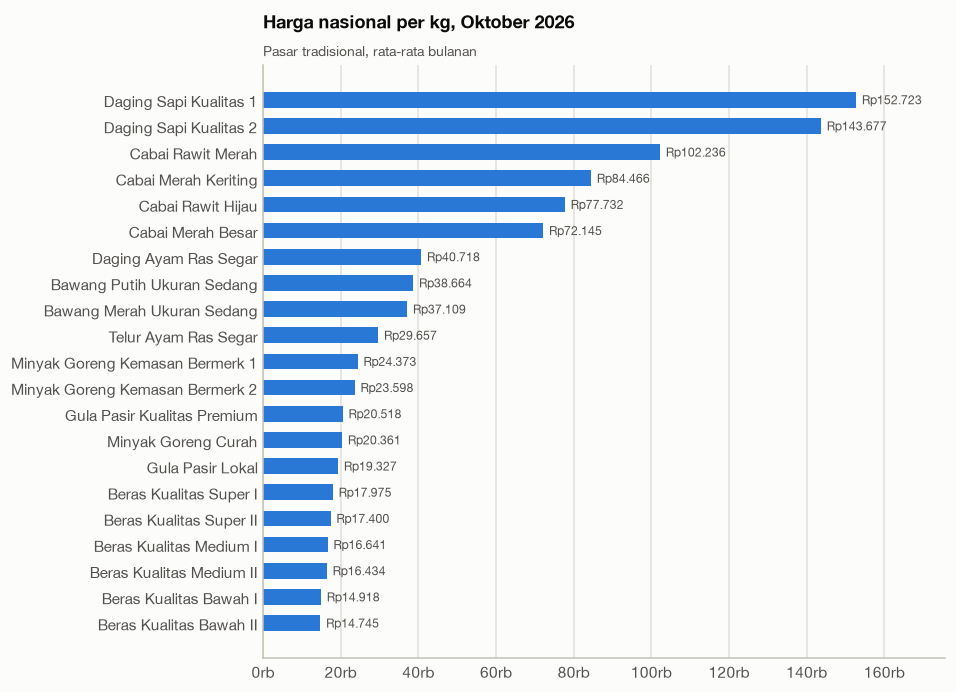

In [5]:
harga_terakhir = query("""
    SELECT k.nama_varian, k.satuan, b.harga_rata
    FROM mart.fact_harga_bulanan AS b
    JOIN mart.dim_komoditas AS k USING (komoditas_id)
    WHERE b.wilayah_id = 0 AND b.jenis_pasar_id = 1 AND b.bulan = '2026-10-01'
    ORDER BY b.harga_rata
""")

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(harga_terakhir.nama_varian, harga_terakhir.harga_rata, height=0.6, color=SERIES[0])
for y, v in enumerate(harga_terakhir.harga_rata):
    ax.text(v + 1500, y, f"Rp{v:,.0f}".replace(",", "."), va="center", fontsize=8, color=INK_2)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1000:.0f}rb"))
ax.set_xlim(0, harga_terakhir.harga_rata.max() * 1.15)
ax.grid(axis="y", visible=False)
ax.set_title("Harga nasional per kg, Oktober 2026", pad=24)
subtitle(ax, "Pasar tradisional, rata-rata bulanan")
save(fig, "01_harga_per_varian")
plt.show()

## 4. Tren 2018–2026 (Q1)

Satu varian per kategori, harga nasional bulanan diindeks ke rata-rata 2018 = 100. Semua panel
memakai sumbu-y yang sama supaya besar ayunannya bisa dibandingkan langsung.

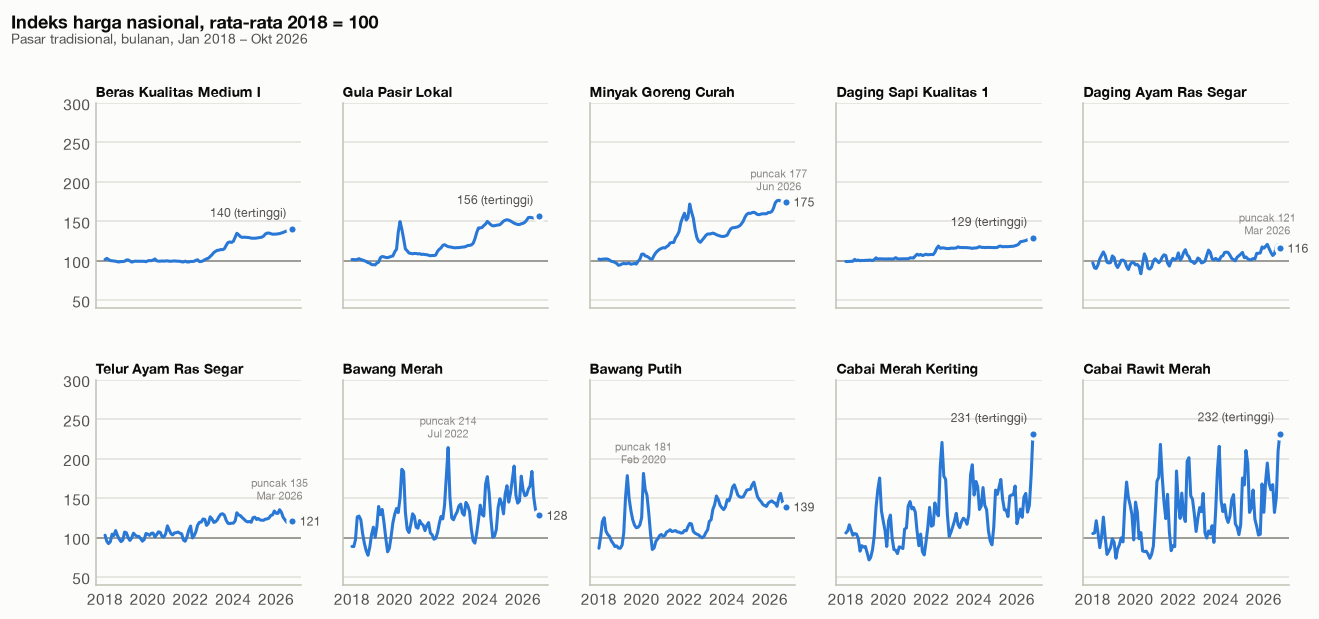

In [6]:
wakil = [
    "Beras Kualitas Medium I", "Gula Pasir Lokal", "Minyak Goreng Curah", "Daging Sapi Kualitas 1",
    "Daging Ayam Ras Segar", "Telur Ayam Ras Segar", "Bawang Merah Ukuran Sedang",
    "Bawang Putih Ukuran Sedang", "Cabai Merah Keriting", "Cabai Rawit Merah",
]
bulanan = query("""
    SELECT b.bulan, k.nama_varian, k.kategori, b.harga_rata
    FROM mart.fact_harga_bulanan AS b
    JOIN mart.dim_komoditas AS k USING (komoditas_id)
    WHERE b.wilayah_id = 0 AND b.jenis_pasar_id = 1
""")
bulanan["bulan"] = pd.to_datetime(bulanan["bulan"])
seri = bulanan.pivot(index="bulan", columns="nama_varian", values="harga_rata")
indeks = 100 * seri / seri.loc["2018"].mean()

fig, axes = plt.subplots(2, 5, figsize=(14, 6), sharex=True, sharey=True)
for ax, var in zip(axes.flat, wakil):
    s = indeks[var]
    ax.axhline(100, color=MUTED, linewidth=1)
    ax.plot(s.index, s, color=SERIES[0])
    ax.plot(s.index[-1], s.iloc[-1], "o", color=SERIES[0], markersize=6,
            markeredgecolor="#fcfcfb", markeredgewidth=2)
    puncak = s.idxmax()
    if puncak >= s.index[-3]:
        # puncak ada di bulan-bulan terakhir: cukup satu label
        ax.annotate(f"{s.iloc[-1]:.0f} (tertinggi)", (s.index[-1], s.iloc[-1]), xytext=(-4, 8),
                    textcoords="offset points", fontsize=8, color=INK_2, ha="right")
    else:
        ax.annotate(f"{s.iloc[-1]:.0f}", (s.index[-1], s.iloc[-1]), xytext=(5, -3),
                    textcoords="offset points", fontsize=8, color=INK_2)
        ax.annotate(f"puncak {s.max():.0f}\n{nama_bulan(puncak)}", (puncak, s.max()), xytext=(0, 5),
                    textcoords="offset points", fontsize=7, color=MUTED, ha="center", va="bottom")
    ax.set_title(var.replace(" Ukuran Sedang", ""), fontsize=9, pad=4)
    ax.grid(axis="x", visible=False)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0, 0].set_ylim(40, 300)
fig.suptitle("Indeks harga nasional, rata-rata 2018 = 100", x=0.07, ha="left", fontweight="bold", fontsize=12)
fig.text(0.07, 0.93, "Pasar tradisional, bulanan, Jan 2018 – Okt 2026", color=INK_2, fontsize=9)
fig.subplots_adjust(top=0.84, hspace=0.35)
save(fig, "01_tren_indeks_harga")
plt.show()

In [7]:
tahunan = seri.groupby(seri.index.year).mean()
(pd.DataFrame({
    "indeks_okt_2026": indeks.iloc[-1],
    "indeks_puncak": indeks.max(),
    "bulan_puncak": indeks.idxmax().map(nama_bulan),
    "kenaikan_2018_2025": tahunan.loc[2025] / tahunan.loc[2018] - 1,
}).loc[wakil])

,indeks_okt_2026,indeks_puncak,bulan_puncak,kenaikan_2018_2025
nama_varian,,,,
Beras Kualitas Medium I,140.070,140.070,Okt 2026,0.319
Gula Pasir Lokal,156.335,156.335,Okt 2026,0.488
Minyak Goreng Curah,174.528,176.654,Jun 2026,0.600
Daging Sapi Kualitas 1,128.546,128.546,Okt 2026,0.180
Daging Ayam Ras Segar,116.022,120.783,Mar 2026,0.063
Telur Ayam Ras Segar,120.958,135.335,Mar 2026,0.251
Bawang Merah Ukuran Sedang,128.259,214.124,Jul 2022,0.567
Bawang Putih Ukuran Sedang,138.942,181.350,Feb 2020,0.526
Cabai Merah Keriting,231.014,231.014,Okt 2026,0.520


**Insight (Q1):**
- **Komoditas pokok naik bertahap dan tidak pernah turun lagi.** Beras datar sampai 2022, lalu
  naik tajam di 2023–2024. Per Oktober 2026, beras (indeks 140), gula (156), dan daging sapi
  (129) ada di titik tertingginya. Minyak goreng curah (175) sedikit di bawah puncak Juni 2026.
- **Cabai dan bawang merah naik-turun tajam** tanpa arah yang jelas dari tahun ke tahun. Bawang
  merah memuncak di Juli 2022 (214).
- **Cabai sedang di rekor tertinggi**: indeks cabai merah keriting dan cabai rawit merah 231–232
  di Oktober 2026. Ini berlawanan dengan pola musiman biasa, di mana September–Oktober adalah
  bulan termurah (Q5). Jadi 2026 adalah tahun yang tidak biasa untuk cabai.
- **Daging ayam paling sedikit naik**: hanya +6% dari 2018 ke 2025.

## 5. Perubahan harga dari bulan ke bulan

Sebaran perubahan harga nasional bulan-ke-bulan (MoM) untuk 21 varian. Kotak = 50% bulan di
tengah, garis = 5%–95%, titik = bulan di luar itu.

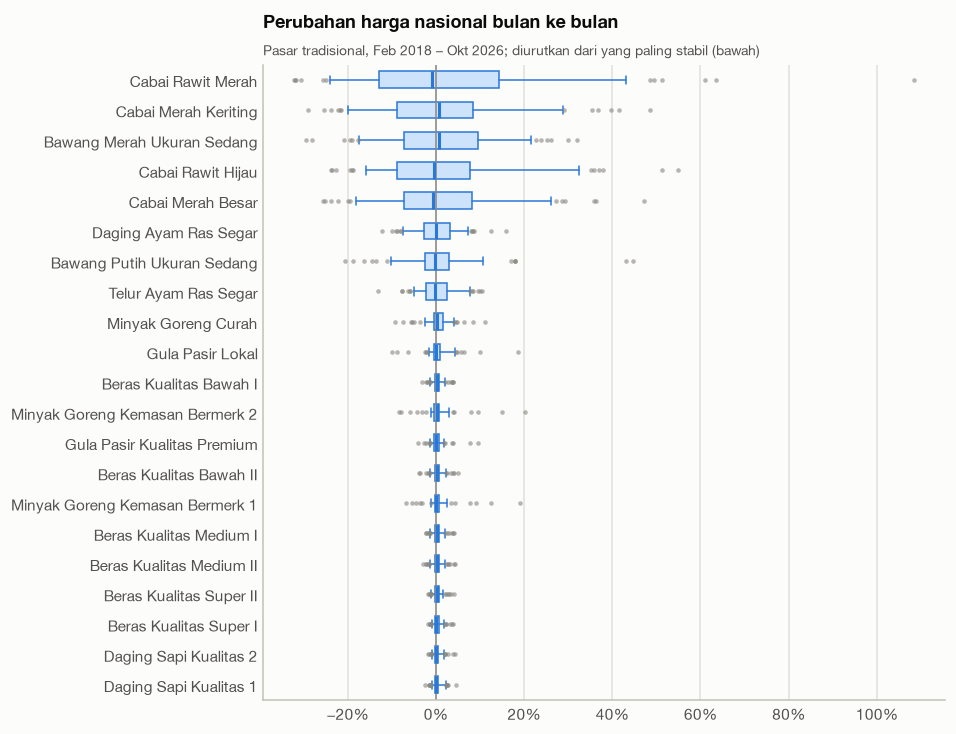

In [8]:
mom = seri.pct_change().iloc[1:]
urutan = (mom.quantile(0.75) - mom.quantile(0.25)).sort_values().index

fig, ax = plt.subplots(figsize=(8, 7.5))
ax.boxplot(
    [mom[c].dropna() for c in urutan], orientation="horizontal", whis=(5, 95), widths=0.55,
    patch_artist=True, showfliers=True,
    boxprops=dict(facecolor=SEQUENTIAL[0], edgecolor=SERIES[0], linewidth=1),
    medianprops=dict(color=SERIES[0], linewidth=2),
    whiskerprops=dict(color=SERIES[0], linewidth=1), capprops=dict(color=SERIES[0], linewidth=1),
    flierprops=dict(marker="o", markersize=3, markerfacecolor=MUTED, markeredgecolor="none", alpha=0.6),
)
ax.set_yticks(range(1, len(urutan) + 1), urutan)
ax.axvline(0, color=MUTED, linewidth=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.grid(axis="y", visible=False)
ax.set_title("Perubahan harga nasional bulan ke bulan", pad=24)
subtitle(ax, "Pasar tradisional, Feb 2018 – Okt 2026; diurutkan dari yang paling stabil (bawah)")
save(fig, "01_sebaran_perubahan_bulanan")
plt.show()

In [9]:
pd.DataFrame({
    "iqr": mom.quantile(0.75) - mom.quantile(0.25),
    "p05": mom.quantile(0.05),
    "p95": mom.quantile(0.95),
    "bulan_naik_lebih_10pct": (mom > 0.10).sum(),
}).loc[urutan[::-1]]

,iqr,p05,p95,bulan_naik_lebih_10pct
nama_varian,,,,
Cabai Rawit Merah,0.272,-0.246,0.474,34
Cabai Merah Keriting,0.171,-0.211,0.290,24
Bawang Merah Ukuran Sedang,0.168,-0.175,0.225,24
Cabai Rawit Hijau,0.166,-0.182,0.347,18
Cabai Merah Besar,0.153,-0.193,0.271,25
Daging Ayam Ras Segar,0.058,-0.078,0.079,2
Bawang Putih Ukuran Sedang,0.054,-0.110,0.157,7
Telur Ayam Ras Segar,0.047,-0.056,0.079,2
Minyak Goreng Curah,0.022,-0.034,0.042,1


**Insight:**
- Ada dua kelompok yang sangat berbeda. **Cabai dan bawang merah**: 50% bulan di tengah
  berubah dalam rentang 15–27 poin persen. Harga cabai rawit merah naik lebih dari 10% dalam
  sebulan di **34 dari 105 bulan**, atau 1 dari 3 bulan.
- **Beras, daging sapi, gula, dan minyak goreng kemasan** hanya berubah ±1% per bulan dan
  tidak pernah naik lebih dari 10% dalam sebulan (beras dan daging sapi: 0 kali).
- Bawang putih ada di tengah, tapi punya beberapa lonjakan besar (2019–2020, saat impor
  tersendat).
- Ini mendukung H1. Uji statistiknya ada di notebook 02.

## 6. Komoditas mana yang bergerak bersama?

Korelasi perubahan harga bulanan antarvarian, diurutkan dengan hierarchical clustering supaya
kelompok yang bergerak bersama terlihat berdampingan.

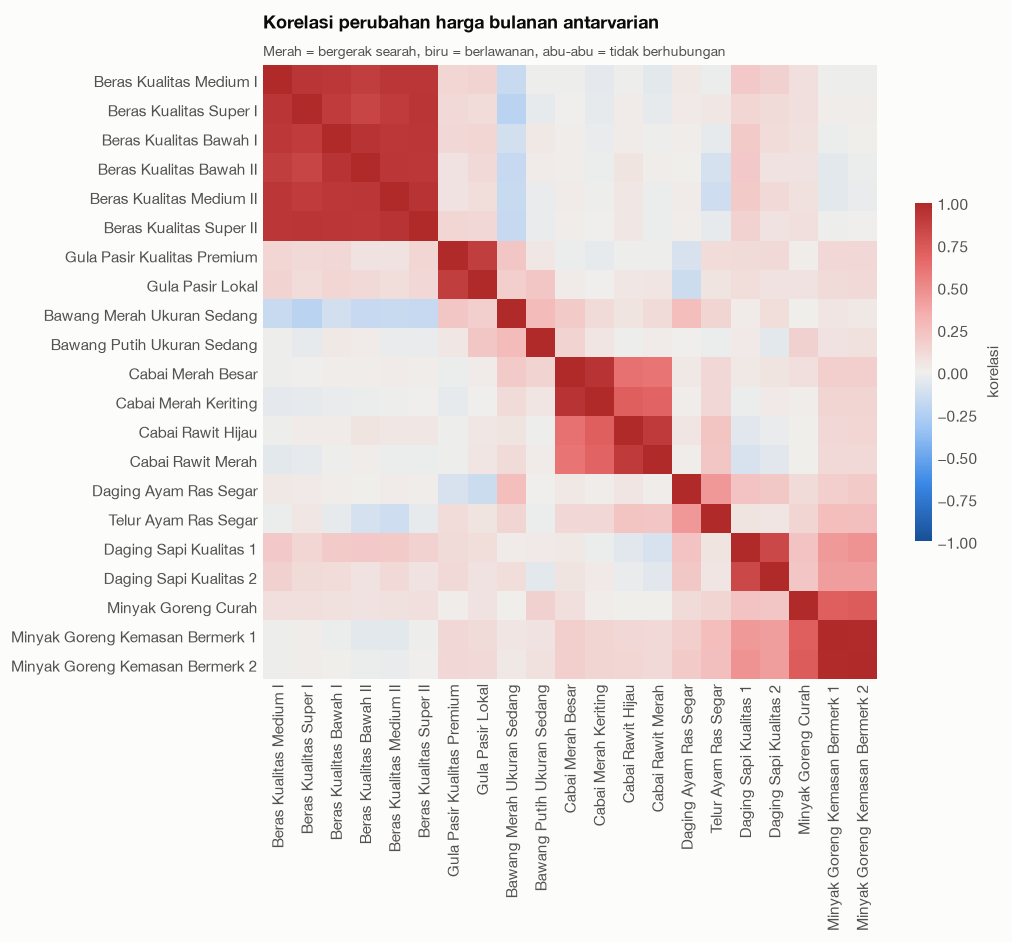

In [10]:
korelasi = mom.corr()
urut = hierarchy.leaves_list(hierarchy.linkage(mom.T.fillna(0), method="average", metric="correlation"))
korelasi = korelasi.iloc[urut, urut]

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(korelasi, cmap=CMAP_DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(korelasi)), korelasi.columns, rotation=90)
ax.set_yticks(range(len(korelasi)), korelasi.index)
ax.grid(False)
ax.spines[:].set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.5)
cb.outline.set_visible(False)
cb.set_label("korelasi", color=INK_2)
ax.set_title("Korelasi perubahan harga bulanan antarvarian", pad=24)
subtitle(ax, "Merah = bergerak searah, biru = berlawanan, abu-abu = tidak berhubungan")
save(fig, "01_korelasi_antarvarian")
plt.show()

In [11]:
kategori = bulanan.drop_duplicates("nama_varian").set_index("nama_varian").kategori
pasangan = korelasi.rename_axis(index="a", columns="b").stack().rename("r").reset_index()
pasangan = pasangan[pasangan.a < pasangan.b]
sama = kategori[pasangan.a].values == kategori[pasangan.b].values
print(f"Median korelasi varian dalam kategori yang sama : {pasangan.r[sama].median():.2f}")
print(f"Median korelasi varian beda kategori            : {pasangan.r[~sama].median():.2f}")
pasangan[~sama].sort_values("r", ascending=False).head(8)

Median korelasi varian dalam kategori yang sama : 0.92
Median korelasi varian beda kategori            : 0.05


,a,b,r
243,Cabai Merah Keriting,Cabai Rawit Hijau,0.709
244,Cabai Merah Keriting,Cabai Rawit Merah,0.682
222,Cabai Merah Besar,Cabai Rawit Hijau,0.623
223,Cabai Merah Besar,Cabai Rawit Merah,0.606
356,Daging Sapi Kualitas 1,Minyak Goreng Kemasan Bermerk 2,0.462
309,Daging Ayam Ras Segar,Telur Ayam Ras Segar,0.442
355,Daging Sapi Kualitas 1,Minyak Goreng Kemasan Bermerk 1,0.434
376,Daging Sapi Kualitas 2,Minyak Goreng Kemasan Bermerk 1,0.418


**Insight:**
- Varian dalam satu kategori bergerak hampir identik (median r = 0,92). Karena itu analisis
  lanjutan cukup memakai satu varian wakil per kategori.
- Antarkategori hampir tidak berhubungan (median r = 0,05). Pengecualiannya **cabai merah dan
  cabai rawit** (r = 0,6–0,7): keduanya praktis satu kelompok risiko.
- Implikasi untuk menu: mengganti cabai merah dengan cabai rawit **tidak** mengurangi risiko
  harga. Menu yang bahan bakunya tersebar di beberapa kategori lebih tahan guncangan.

## 7. Contoh data yang ditandai anomali

Di Fase 2, harga ditandai `is_anomali` kalau menyimpang > 25% dari rata-rata 5 hari sebelum
**dan** sesudahnya, ke arah yang sama. Totalnya hanya 995 sel (0,03%). Contoh: harga telur
nasional sekitar Iduladha 2020.

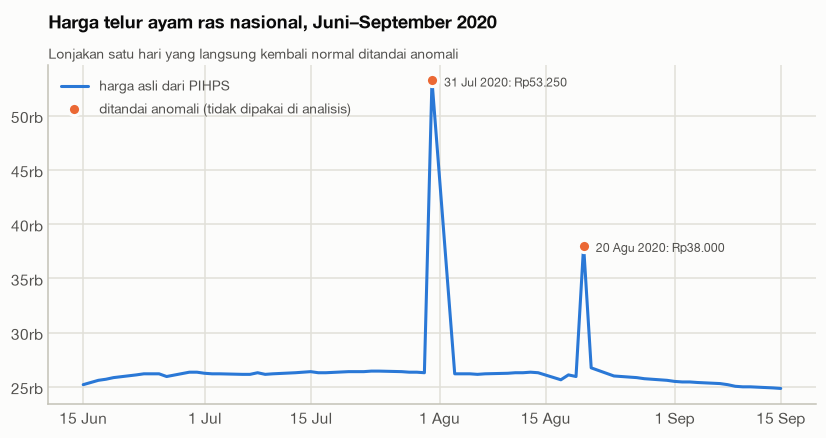

In [12]:
telur = query("""
    SELECT f.tanggal, f.harga_asli, f.is_anomali
    FROM mart.fact_harga_harian AS f
    JOIN mart.dim_komoditas AS k USING (komoditas_id)
    WHERE f.wilayah_id = 0 AND f.jenis_pasar_id = 1 AND k.nama_varian = 'Telur Ayam Ras Segar'
      AND f.tanggal BETWEEN '2020-06-15' AND '2020-09-15'
    ORDER BY f.tanggal
""")
telur["tanggal"] = pd.to_datetime(telur["tanggal"])
anomali = telur[telur.is_anomali]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(telur.tanggal, telur.harga_asli, color=SERIES[0], label="harga asli dari PIHPS")
ax.plot(anomali.tanggal, anomali.harga_asli, "o", color=SERIES[1], markersize=8,
        markeredgecolor="#fcfcfb", markeredgewidth=2, label="ditandai anomali (tidak dipakai di analisis)")
for _, r in anomali.iterrows():
    label = f"{r.tanggal.day} {nama_bulan(r.tanggal)}: Rp{r.harga_asli:,.0f}".replace(",", ".")
    ax.annotate(label, (r.tanggal, r.harga_asli), xytext=(8, -4), textcoords="offset points",
                fontsize=8, color=INK_2)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1000:.0f}rb"))
sumbu_tanggal(ax)
ax.legend(loc="upper left")
ax.set_title("Harga telur ayam ras nasional, Juni–September 2020", pad=24)
subtitle(ax, "Lonjakan satu hari yang langsung kembali normal ditandai anomali")
save(fig, "01_contoh_anomali")
plt.show()

## Ringkasan EDA

1. Data pasar tradisional 94% lengkap. Gorontalo paling banyak varian kosong, jadi perbandingan
   antarprovinsi memakai indeks per varian.
2. Komoditas pokok (beras, gula, minyak goreng, daging sapi) naik bertahap ke titik tertinggi di
   2026. Cabai dan bawang merah naik-turun tajam, dan cabai sedang di rekor tertinggi.
3. Cabai dan bawang merah berubah 15–27 poin persen per bulan, sedangkan beras dan daging sapi ±1%.
4. Varian dalam satu kategori bergerak hampir identik; antarkategori hampir independen, kecuali
   cabai merah dan cabai rawit.

Lanjut ke [02_uji_hipotesis.ipynb](02_uji_hipotesis.ipynb).